Total Sampel    : 569
Training Samples: 398 (70%)
Testing Samples : 171 (30%)

=== Classification Report: Logistic Regression ===
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        64
      benign       0.99      0.99      0.99       107

    accuracy                           0.99       171
   macro avg       0.99      0.99      0.99       171
weighted avg       0.99      0.99      0.99       171

=== Classification Report: Random Forest ===
              precision    recall  f1-score   support

   malignant       0.92      0.91      0.91        64
      benign       0.94      0.95      0.95       107

    accuracy                           0.94       171
   macro avg       0.93      0.93      0.93       171
weighted avg       0.94      0.94      0.94       171

=== Perbandingan Performa Model ===
          Algoritma  Accuracy (%)  Precision  Recall  F1-Score  ROC-AUC
Logistic Regression         98.83     0.9907  0.9907    0.9907 

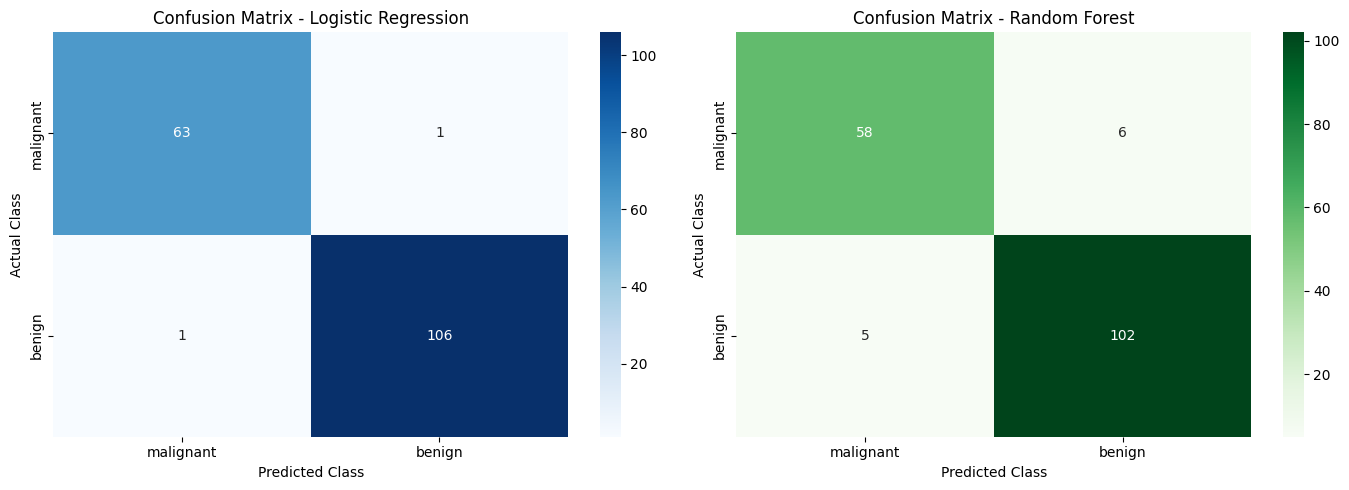

In [5]:
# ==========================================
# 1. IMPORT LIBRARIES
# ==========================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# ==========================================
# 2. LOAD DATASET & SPLITTING (70% TRAIN, 30% TEST)
# ==========================================
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

# Pembagian dataset 70% training dan 30% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,      # 30% testing
    random_state=42,
    stratify=y
)

print(f"Total Sampel    : {X.shape[0]}")
print(f"Training Samples: {X_train.shape[0]} (70%)")
print(f"Testing Samples : {X_test.shape[0]} (30%)\n")

# ==========================================
# 3. MEMBANGUN & MELATIH MODEL
# ==========================================
# Model 1: Logistic Regression (dengan StandardScaler)
model_lr = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42)
)
model_lr.fit(X_train, y_train)

# Model 2: Random Forest Classifier
model_rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)
model_rf.fit(X_train, y_train)

# ==========================================
# 4. PREDIKSI & EVALUASI PERFORMA
# ==========================================
models = {
    "Logistic Regression": model_lr,
    "Random Forest": model_rf
}

results = []

for name, model in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)

    results.append({
        "Algoritma": name,
        "Accuracy (%)": round(acc * 100, 2),
        "Precision": round(prec, 4),
        "Recall": round(rec, 4),
        "F1-Score": round(f1, 4),
        "ROC-AUC": round(auc, 4)
    })

    print(f"=== Classification Report: {name} ===")
    print(classification_report(y_test, y_pred, target_names=data.target_names))

# Menampilkan tabel perbandingan metrik
df_results = pd.DataFrame(results)
print("=== Perbandingan Performa Model ===")
print(df_results.to_string(index=False))

# ==========================================
# 5. VISUALISASI CONFUSION MATRIX KEDUA MODEL
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for idx, (name, model) in enumerate(models.items()):
    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues" if idx == 0 else "Greens",
        xticklabels=data.target_names,
        yticklabels=data.target_names,
        ax=axes[idx]
    )
    axes[idx].set_title(f"Confusion Matrix - {name}")
    axes[idx].set_xlabel("Predicted Class")
    axes[idx].set_ylabel("Actual Class")

plt.tight_layout()
plt.show()